In [11]:
import pandas as pd

In [12]:
main_df=pd.read_csv("Featured_dataset.csv")
main_df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,...,Estimated_Annual_Spend,Loyalty_Score,Promo_Dependency,Annual_Spend,Value_Tier,Customer_Value_Index,Satisfaction_Level,Tenure_Proxy,Bargain_Hunter,Ideal_Customer_Score
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,1378,16.2,2,1378,High Value,854.36,Medium,New,1,486.18
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,1664,11.4,2,1664,Premium Value,1031.68,Medium,New,1,583.88
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,3796,30.2,2,3796,Premium Value,2353.52,Medium,Growing,1,1334.28
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,...,4680,40.6,2,4680,Premium Value,3276.00,Medium,Veteran,1,1649.00
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,...,49,13.0,2,49,Low Value,26.46,Low,Veteran,1,24.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,...,1456,33.6,0,1456,High Value,1223.04,High,Veteran,0,517.26
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,...,1274,26.8,0,1274,High Value,1146.60,High,Veteran,0,455.45
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,...,132,11.2,0,132,Low Value,76.56,Low,Growing,0,51.87
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,...,4004,30.4,0,4004,Premium Value,3043.04,Medium,Growing,0,1407.34


In [13]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [14]:
df=main_df.copy(deep=True)
df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,...,Estimated_Annual_Spend,Loyalty_Score,Promo_Dependency,Annual_Spend,Value_Tier,Customer_Value_Index,Satisfaction_Level,Tenure_Proxy,Bargain_Hunter,Ideal_Customer_Score
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,1378,16.2,2,1378,High Value,854.36,Medium,New,1,486.18
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,1664,11.4,2,1664,Premium Value,1031.68,Medium,New,1,583.88
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,3796,30.2,2,3796,Premium Value,2353.52,Medium,Growing,1,1334.28
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,...,4680,40.6,2,4680,Premium Value,3276.00,Medium,Veteran,1,1649.00
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,...,49,13.0,2,49,Low Value,26.46,Low,Veteran,1,24.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,...,1456,33.6,0,1456,High Value,1223.04,High,Veteran,0,517.26
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,...,1274,26.8,0,1274,High Value,1146.60,High,Veteran,0,455.45
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,...,132,11.2,0,132,Low Value,76.56,Low,Growing,0,51.87
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,...,4004,30.4,0,4004,Premium Value,3043.04,Medium,Growing,0,1407.34


In [10]:
df[['Promo Code Used','Estimated_Annual_Spend']].groupby(by='Promo Code Used').mean()

,Estimated_Annual_Spend
Promo Code Used,
0,1041.743140
1,1035.202147


In [ ]:
df['Estimated_Annual_Spend']

0       1378
1       1664
2       3796
3       4680
4         49
        ... 
3895    1456
3896    1274
3897     132
3898    4004
3899     324
Name: Estimated_Annual_Spend, Length: 3900, dtype: int64

In [15]:
spend_promo = df[df['Promo Code Used'] == 1]['Purchase Amount (USD)']
spend_promo

0       53
1       64
2       73
3       90
4       49
        ..
1672    73
1673    62
1674    56
1675    90
1676    44
Name: Purchase Amount (USD), Length: 1677, dtype: int64

In [16]:
spend_promo = df[df['Promo Code Used'] == 1]['Purchase Amount (USD)']
spend_no_promo = df[df['Promo Code Used'] == 0]['Purchase Amount (USD)']
t_stat, t_pval = stats.ttest_ind(spend_promo, spend_no_promo, equal_var=False)
print(f"[Welch's t-test] Spend vs Promo: t-stat = {t_stat:.4f}, p-value = {t_pval:.4f}")

[Welch's t-test] Spend vs Promo: t-stat = -1.1122, p-value = 0.2661


In [18]:
group2 = df[df['Promo_Dependency'] == 2]['Review Rating']
group2

0       3.1
1       3.1
2       3.1
3       3.5
4       2.7
       ... 
1672    3.8
1673    3.4
1674    3.2
1675    4.7
1676    3.1
Name: Review Rating, Length: 1677, dtype: float64

In [ ]:
import scipy.stats as stats

# Group customer review ratings by their assigned Value Tier
vt_groups = [group['Review Rating'].dropna() for name, group in df.groupby('Value_Tier')]

# Run One-Way ANOVA
f_stat, p_val = stats.f_oneway(*vt_groups)

print(f"F-statistic = {f_stat:.4f}, p-value = {p_val:.4f}")

[ANOVA] Review Rating across Value Tiers: F=0.8370, p-value=0.4734


In [22]:
# C. Chi-Square Test: Subscription Status vs Discount Applied
contingency_tab = pd.crosstab(df['Subscription Status'], df['Discount Applied'])
chi2, chi_pval, dof, _ = stats.chi2_contingency(contingency_tab)
print(f"[Chi-Square] Subscription vs Discount: Chi2 = {chi2:.4f}, p-value = {chi_pval:.4f}")

[Chi-Square] Subscription vs Discount: Chi2 = 1908.9214, p-value = 0.0000


In [24]:
#customer segment level: Value_Tier vs Discount Applied
contingency_vt = pd.crosstab(df['Value_Tier'], df['Discount Applied'])
chi2, p_val, dof, _ = stats.chi2_contingency(contingency_vt)
print(f"Chi2 = {chi2:.4f}, p-value = {p_val:.4f}")

Chi2 = 0.1842, p-value = 0.9801


In [23]:
#Category vs Discount Applied (Product Level)
contingency_cat = pd.crosstab(df['Category'], df['Discount Applied'])
chi2, p_val, dof, _ = stats.chi2_contingency(contingency_cat)
print(f"Chi2 = {chi2:.4f}, p-value = {p_val:.4f}")

Chi2 = 1.2003, p-value = 0.7529


--- K-Means Evaluation Metrics ---
K= 2 | WCSS (Inertia):   18264.42 | Silhouette: 0.2202 | Calinski-Harabasz: 1096.05
K= 3 | WCSS (Inertia):   15620.28 | Silhouette: 0.1752 | Calinski-Harabasz:  970.47
K= 4 | WCSS (Inertia):   14002.28 | Silhouette: 0.1734 | Calinski-Harabasz:  871.61
K= 5 | WCSS (Inertia):   12748.20 | Silhouette: 0.1753 | Calinski-Harabasz:  813.62
K= 6 | WCSS (Inertia):   11862.15 | Silhouette: 0.1732 | Calinski-Harabasz:  757.52
K= 7 | WCSS (Inertia):   11196.24 | Silhouette: 0.1688 | Calinski-Harabasz:  707.23
K= 8 | WCSS (Inertia):   10472.46 | Silhouette: 0.1776 | Calinski-Harabasz:  686.35
K= 9 | WCSS (Inertia):    9933.67 | Silhouette: 0.1781 | Calinski-Harabasz:  659.34
K=10 | WCSS (Inertia):    9271.96 | Silhouette: 0.1895 | Calinski-Harabasz:  658.59


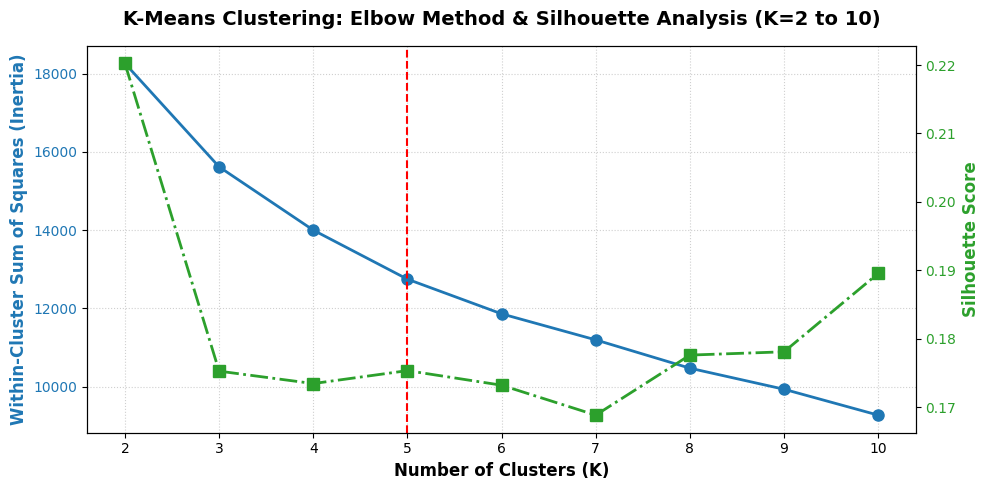

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# 1. Load the engineered dataset
df = pd.read_csv("Featured_dataset.csv")

# 2. Select numerical features for K-Means clustering
cluster_features = [
    'Age', 
    'Purchase Amount (USD)', 
    'Review Rating', 
    'Previous Purchases', 
    'Purchase_Freq_Score', 
    'Loyalty_Score'
]

X = df[cluster_features]

# 3. Standardize features to mean=0, std=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Iterate K-Means across K = 2 to 10
K_range = range(2, 11)
inertias = []
silhouettes = []
ch_scores = []

print("--- K-Means Evaluation Metrics ---")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    
    wcss = km.inertia_
    sil = silhouette_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    
    inertias.append(wcss)
    silhouettes.append(sil)
    ch_scores.append(ch)
    
    print(f"K={k:2d} | WCSS (Inertia): {wcss:10.2f} | Silhouette: {sil:.4f} | Calinski-Harabasz: {ch:7.2f}")

# 5. Plot the Elbow Curve & Silhouette Scores
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Inertia (WCSS) on left axis
color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Within-Cluster Sum of Squares (Inertia)', color=color, fontsize=12, fontweight='bold')
ax1.plot(K_range, inertias, marker='o', color=color, linewidth=2, markersize=8, label='Inertia (WCSS)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.axvline(x=5, color='red', linestyle='--', linewidth=1.5, label='Selected K=5')
ax1.grid(True, linestyle=':', alpha=0.6)

# Plot Silhouette Score on right axis
ax2 = ax1.twinx()  
color = 'tab:green'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=12, fontweight='bold')
ax2.plot(K_range, silhouettes, marker='s', color=color, linewidth=2, markersize=8, linestyle='-.', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('K-Means Clustering: Elbow Method & Silhouette Analysis (K=2 to 10)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

In [28]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load dataset
df = pd.read_csv("Featured_dataset.csv")

# 2. Re-run K-Means (K=5)
cluster_features = ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases', 'Purchase_Freq_Score', 'Loyalty_Score']
X = df[cluster_features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 3. Compute cluster feature averages
cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('Customer ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Purchase_Amount=('Purchase Amount (USD)', 'mean'),
    Avg_Review_Rating=('Review Rating', 'mean'),
    Avg_Previous_Purchases=('Previous Purchases', 'mean'),
    Avg_Purchase_Freq_Score=('Purchase_Freq_Score', 'mean'),
    Avg_Loyalty_Score=('Loyalty_Score', 'mean'),
    Avg_Annual_Spend=('Estimated_Annual_Spend', 'mean'),
    Total_Revenue=('Estimated_Annual_Spend', 'sum'),
    Discount_Rate=('Discount Applied', 'mean')
).reset_index()

total_rev = df['Estimated_Annual_Spend'].sum()
cluster_summary['Customer_Pct'] = (cluster_summary['Customer_Count'] / len(df)) * 100
cluster_summary['Revenue_Pct'] = (cluster_summary['Total_Revenue'] / total_rev) * 100

# 4. Overall Dataset Baseline Average
overall_avg = pd.DataFrame([{
    'Cluster': 'OVERALL AVG',
    'Customer_Count': len(df),
    'Avg_Age': df['Age'].mean(),
    'Avg_Purchase_Amount': df['Purchase Amount (USD)'].mean(),
    'Avg_Review_Rating': df['Review Rating'].mean(),
    'Avg_Previous_Purchases': df['Previous Purchases'].mean(),
    'Avg_Purchase_Freq_Score': df['Purchase_Freq_Score'].mean(),
    'Avg_Loyalty_Score': df['Loyalty_Score'].mean(),
    'Avg_Annual_Spend': df['Estimated_Annual_Spend'].mean(),
    'Total_Revenue': total_rev,
    'Discount_Rate': df['Discount Applied'].mean(),
    'Customer_Pct': 100.0,
    'Revenue_Pct': 100.0
}])

# Combine and print
summary_table = pd.concat([cluster_summary, overall_avg], ignore_index=True)

# Map labels to show the final decision
label_map = {
    0: 'Mature Low-Frequency Buyers',
    1: 'High-Basket Veteran Spenders',
    2: 'Young Casual / Emerging Shoppers',
    3: 'VIP Power Buyers (Weekly Spenders)',
    4: 'Low-Basket Veteran Buyers',
    'OVERALL AVG': 'OVERALL DATASET BASELINE'
}
summary_table['Persona_Label'] = summary_table['Cluster'].map(label_map)

print("=== CLUSTER PROFILING SUMMARY TABLE FOR LABELING DECISIONS ===")
print(summary_table[['Cluster', 'Persona_Label', 'Customer_Pct', 'Revenue_Pct', 'Avg_Age', 'Avg_Purchase_Amount', 'Avg_Previous_Purchases', 'Avg_Purchase_Freq_Score', 'Avg_Annual_Spend']].round(2).to_string(index=False))

=== CLUSTER PROFILING SUMMARY TABLE FOR LABELING DECISIONS ===
    Cluster                      Persona_Label  Customer_Pct  Revenue_Pct  Avg_Age  Avg_Purchase_Amount  Avg_Previous_Purchases  Avg_Purchase_Freq_Score  Avg_Annual_Spend
          0        Mature Low-Frequency Buyers         20.08        11.28    58.09                62.74                   13.50                     9.17            583.76
          1       High-Basket Veteran Spenders         22.10        23.76    43.28                80.72                   37.75                    13.93           1116.87
          2   Young Casual / Emerging Shoppers         23.41        14.48    29.97                57.47                   13.64                    11.33            642.49
          3 VIP Power Buyers (Weekly Spenders)         13.82        40.79    44.65                58.97                   25.77                    52.00           3066.55
          4          Low-Basket Veteran Buyers         20.59         9.69    46.88